[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HesusG/dammg-supervisado/blob/main/notebooks/demos/D1_ecuacion_normal.ipynb)

# D1 · La ecuación normal es una proyección ortogonal

*DAMMG · Módulo VI · Aprendizaje supervisado · FC-UNAM*

**Recuerden (Mód I).** $\operatorname{col}(X)$ es un subespacio; si $\vec r\perp$ cada columna, $\vec r$ es perpendicular a todo el subespacio; Pitágoras.

**Supuestos.** La primera columna de $X$ es de unos (así $b$ es una entrada de $\vec w$). Costo sin regularizar. $\hat{\vec w}$ es único solo si las columnas son linealmente independientes; $\hat{\vec y}$ es único siempre.

**La idea.** Las ecuaciones normales $X^\top X\hat{\vec w}=X^\top\vec y$ dicen $X^\top\vec r=\vec 0$: el residual $\vec r=\vec y-X\hat{\vec w}$ es perpendicular a cada columna. Aquí lo comprobamos con números y vemos qué pasa cuando dos columnas se vuelven casi iguales.

La derivación completa está en `anexos/derivaciones.pdf`.

In [1]:
%matplotlib inline
import sys, pathlib
# dammg_utils vive en notebooks/ (en Colab se descarga junto al notebook)
for p in (pathlib.Path("..").resolve(), pathlib.Path(".").resolve()):
    if (p / "dammg_utils.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import matplotlib.pyplot as plt
from dammg_utils import estilo_dammg, COLORES
estilo_dammg()
C = COLORES
np.set_printoptions(precision=4, suppress=True)

## Parámetros
Si los controles no aparecen (por ejemplo, en el PDF), cambien el valor aquí y ejecuten de nuevo.

In [2]:
# Parámetro del ¿qué pasa si...?
RHO = 0.90   # correlación entre las dos variables (0 = independientes, 0.999 = casi duplicadas)
SEMILLA = 0

## La identidad, con números

Xᵀ r (debería ser ~0): [ 0. -0. -0.]
suma de residuales: 6.56e-14
‖H² − H‖ = 1.77e-15   traza(H) = 3.000 (= p = 3)
κ(XᵀX) = 14   κ(X)² = 14


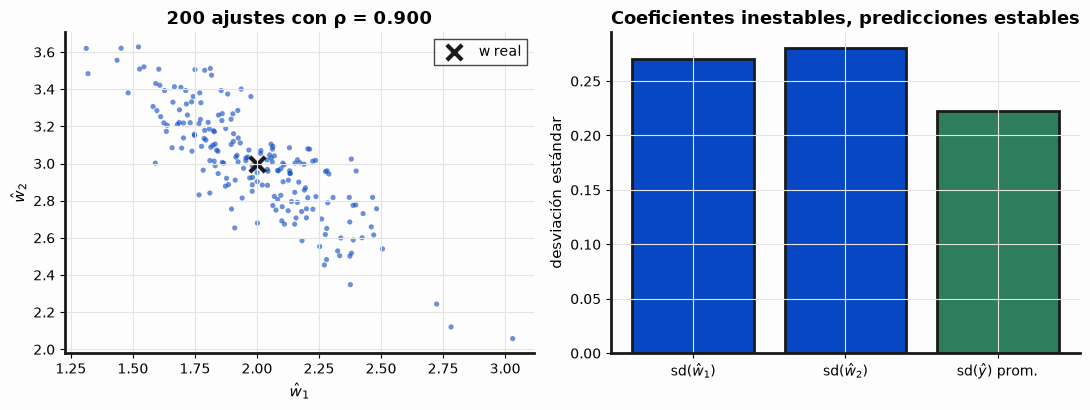

In [3]:
def demo(rho=RHO, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    m = 60
    x1 = rng.normal(size=m)
    x2 = rho * x1 + np.sqrt(1 - rho**2) * rng.normal(size=m)
    X = np.column_stack([np.ones(m), x1, x2])
    w_real = np.array([1.0, 2.0, 3.0])
    y = X @ w_real + rng.normal(scale=1.0, size=m)

    w, *_ = np.linalg.lstsq(X, y, rcond=None)     # QR/SVD, no invierte XᵀX
    yhat = X @ w
    r = y - yhat
    H = X @ np.linalg.solve(X.T @ X, X.T)

    print("Xᵀ r (debería ser ~0):", X.T @ r)
    print(f"suma de residuales: {r.sum():.2e}")
    print(f"‖H² − H‖ = {np.linalg.norm(H @ H - H):.2e}   traza(H) = {np.trace(H):.3f} (= p = 3)")
    print(f"κ(XᵀX) = {np.linalg.cond(X.T @ X):,.0f}   κ(X)² = {np.linalg.cond(X)**2:,.0f}")
    assert np.allclose(X.T @ r, 0, atol=1e-8)

    # Repetimos el experimento con otro ruido: ¿cuánto se mueven ŵ y ŷ?
    W, Y = [], []
    for _ in range(200):
        yb = X @ w_real + rng.normal(scale=1.0, size=m)
        wb, *_ = np.linalg.lstsq(X, yb, rcond=None)
        W.append(wb); Y.append(X @ wb)
    W, Y = np.array(W), np.array(Y)

    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].scatter(W[:, 1], W[:, 2], s=14, color=C["w"], edgecolor="none", alpha=0.6)
    ax[0].scatter([2], [3], marker="x", s=120, color=C["tinta"], linewidth=3, label="w real")
    ax[0].set(xlabel="$\\hat w_1$", ylabel="$\\hat w_2$", title=f"200 ajustes con ρ = {rho:.3f}")
    ax[0].legend(loc="upper right")
    ax[1].bar(["sd($\\hat w_1$)", "sd($\\hat w_2$)", "sd($\\hat y$) prom."],
              [W[:, 1].std(), W[:, 2].std(), Y.std(axis=0).mean()],
              color=[C["w"], C["w"], C["yhat"]], edgecolor=C["tinta"], linewidth=2)
    ax[1].set(title="Coeficientes inestables, predicciones estables", ylabel="desviación estándar")
    fig.tight_layout(); plt.show()

demo()

**¿Qué pasa si…?** Antes de mover el control, escriban su predicción: si $\rho\to 1$, ¿qué le pasa a la nube de $(\hat w_1,\hat w_2)$? ¿Y a la desviación de $\hat y$? ¿Sigue valiendo $X^\top\vec r\approx 0$?

Respuesta esperada: $X^\top \vec r\approx 0$ siempre (es la definición de proyección). La nube se estira a lo largo de la recta $\hat w_1+\hat w_2\approx 5$: el modelo solo sabe la suma, no el reparto. Las predicciones casi no cambian. Esto motiva Ridge (D2).

In [4]:
# ¿Qué pasa si...? Muevan el control. Sin ipywidgets: cambien el parámetro arriba y vuelvan a ejecutar.
try:
    import ipywidgets as W
    W.interact(demo, rho=W.FloatSlider(value=RHO, min=0.0, max=0.999, step=0.001, readout_format='.3f', description='ρ', continuous_update=False), semilla=W.fixed(SEMILLA))
except ImportError:
    print('ipywidgets no está instalado: usen la celda de parámetros.')